# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Dự báo trước một ngày nhu cầu sạc xe điện ở 275 vùng đô thị với khoảng dự báo còn trung thực trong dịp Tết và khi mưa

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** hai notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy

In [2]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** ô in đường dẫn của từng file cần có. Nếu tải tự động lỗi hoặc thiếu file, tải tay tại `github.com/IntelligentSystemsLab/UrbanEV (folder data)`, chép vào `data/raw/` rồi chạy lại ô này.

In [3]:
FILES = [('https://raw.githubusercontent.com/IntelligentSystemsLab/UrbanEV/main/data/volume.csv', 'volume.csv'), ('https://raw.githubusercontent.com/IntelligentSystemsLab/UrbanEV/main/data/occupancy.csv', 'occupancy.csv'), ('https://raw.githubusercontent.com/IntelligentSystemsLab/UrbanEV/main/data/e_price.csv', 'e_price.csv'), ('https://raw.githubusercontent.com/IntelligentSystemsLab/UrbanEV/main/data/s_price.csv', 's_price.csv'), ('https://raw.githubusercontent.com/IntelligentSystemsLab/UrbanEV/main/data/weather_central.csv', 'weather_central.csv'), ('https://raw.githubusercontent.com/IntelligentSystemsLab/UrbanEV/main/data/inf.csv', 'inf.csv')]
NEED = ['volume.csv', 'occupancy.csv', 'e_price.csv', 's_price.csv', 'weather_central.csv', 'inf.csv']
have = lambda: [glob.glob('data/raw/**/' + n, recursive=True) for n in NEED]
if not all(have()):
    for url, name in FILES:
        try: fetch(url, name)
        except Exception as e: print('download failed:', name, e)
    unzip_all()
for n, hit in zip(NEED, have()):
    assert hit, 'missing ' + n + ': download by hand from github.com/IntelligentSystemsLab/UrbanEV (folder data) into data/raw and run this cell again'
    print(n, '->', hit[0], os.path.getsize(hit[0]) // 1024, 'kB')

volume.csv -> data/raw\volume.csv 16117 kB
occupancy.csv -> data/raw\occupancy.csv 5384 kB
e_price.csv -> data/raw\e_price.csv 11763 kB
s_price.csv -> data/raw\s_price.csv 14615 kB
weather_central.csv -> data/raw\weather_central.csv 177 kB
inf.csv -> data/raw\inf.csv 72 kB


## Bước 1b. Nạp dữ liệu

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số dòng, số cột với mô tả của bộ dữ liệu trong đề cương; nếu khác thì ghi lại con số thật.

In [4]:
# Step 1b: UrbanEV (Li et al., 2025): hourly electric vehicle charging in 275 zones of Shenzhen, Sept 2022 to Feb 2023, 1.19 million zone-hours
# download (plain CSV files, no account): https://raw.githubusercontent.com/IntelligentSystemsLab/UrbanEV/main/data/<file>
import pandas as pd, numpy as np, glob
F = lambda name: glob.glob('data/raw/**/' + name, recursive=True)[0]
def long(name, value):                                   # files are wide: one row per hour, one column per zone
    w = pd.read_csv(F(name)); return w.melt(id_vars='time', var_name='zone', value_name=value)
df = long('volume.csv', 'volume')
for name, value in [('occupancy.csv', 'occupancy'), ('e_price.csv', 'e_price'), ('s_price.csv', 's_price')]:
    df[value] = long(name, value)[value].to_numpy()       # same shape and order in every file
df['ts'] = pd.to_datetime(df.time); df['zone'] = df.zone.astype(int)
wx = pd.read_csv(F('weather_central.csv')); wx['ts'] = pd.to_datetime(wx.time, format='%Y/%m/%d %H:%M')
inf = pd.read_csv(F('inf.csv')).groupby('TAZID').agg(piles=('charge_count', 'sum'), stations=('station_id', 'size'), area=('area', 'first')).reset_index()
df = df.merge(wx[['ts', 'T', 'U', 'nRAIN']], on='ts', how='left').merge(inf, left_on='zone', right_on='TAZID', how='left')
print(df.shape, df.zone.nunique(), 'zones', df.ts.min(), df.ts.max()); print(df[['volume', 'occupancy', 'e_price', 'piles']].describe().T[['mean', '50%', 'max']])

(1194600, 14) 275 zones 2022-09-01 00:00:00 2023-02-28 23:00:00
                 mean        50%      max
volume     260.884664  53.666667  16732.5
occupancy   17.866457  11.000000    373.0
e_price      0.951196   0.960000      1.8
piles       63.752727  48.000000    373.0


## Bước 2. Làm sạch có nhật ký

- **Làm gì:** kiểm tra miền giá trị, loại dòng lỗi, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [5]:
# Step 2: grid check, calendar and weather flags, cleaning log
log = [['zone-hours', len(df)], ['zones', df.zone.nunique()], ['missing cells', int(df[['volume', 'occupancy', 'e_price', 'T']].isna().sum().sum())]]
steps = df.groupby('zone').ts.nunique(); log.append(['zones with a complete hourly grid', int((steps == steps.max()).sum())])
df = df[df.volume >= 0]; log.append(['non-negative volume', len(df)])
day = df.ts.dt.normalize(); H = lambda a, b: (day >= a) & (day <= b)
df['festival'] = H('2023-01-21', '2023-01-27').astype(int)                # Spring Festival public holiday
df['holiday'] = (H('2022-09-10', '2022-09-12') | H('2022-10-01', '2022-10-07') | H('2022-12-31', '2023-01-02') | H('2023-01-21', '2023-01-27')).astype(int)
df['rain'] = (df.nRAIN > 0).astype(int); df['hour'] = df.ts.dt.hour; df['dow'] = df.ts.dt.dayofweek
df['piles'] = df.piles.fillna(df.piles.median())
keep = ['zone', 'ts', 'volume', 'occupancy', 'e_price', 's_price', 'T', 'U', 'nRAIN', 'rain', 'holiday', 'festival', 'hour', 'dow', 'piles']
log += [['holiday hours per zone', int(df.holiday.sum() / df.zone.nunique())], ['rainy hours per zone', int(df.rain.sum() / df.zone.nunique())]]
pd.DataFrame(log, columns=['step', 'value']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
df[keep].to_parquet('data/processed/urbanev.parquet', index=False); print(df[keep].shape)

[['zone-hours', 1194600], ['zones', 275], ['missing cells', 0], ['zones with a complete hourly grid', 275], ['non-negative volume', 1194600], ['holiday hours per zone', 480], ['rainy hours per zone', 372]]
(1194600, 15)


## Bước 2b. Hiểu dữ liệu trước khi đặt câu hỏi

Mười ô dưới đây đọc lại bảng đã làm sạch và trả lời lần lượt: bảng có những cột gì, phân phối ra sao, thiếu ở đâu, có giá trị lạ không, cột nào liên quan tới mục tiêu và mục tiêu khác nhau thế nào giữa các nhóm. **Quy tắc:** sau mỗi ô, nhóm viết một câu nhận xét có số vào dòng Nhận xét. Hình và mô hình chỉ tốt khi nhóm hiểu dữ liệu ở bước này.

### 2b.1 Nạp bảng sạch và xem năm dòng đầu

- **Làm gì:** đọc file parquet, chọn cột mục tiêu và cột nhóm, lấy mẫu cố định để vẽ nhanh.
- **Kiểm tra:** số dòng khớp với nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [6]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
E = pd.read_parquet('data/processed/urbanev.parquet'); TGT, GRP = 'volume', 'hour'
S = E.sample(min(len(E), 50_000), random_state=0)          # a fixed sample keeps every plot fast
NUM = [c for c in S.select_dtypes('number').columns if c != 'row_id' and S[c].nunique() > 1]
print(E.shape[0], 'rows,', E.shape[1], 'columns;', len(NUM), 'numeric columns; target:', TGT, '; group:', GRP); display(E.head(5))

1194600 rows, 15 columns; 14 numeric columns; target: volume ; group: hour


,zone,ts,volume,occupancy,e_price,s_price,T,U,nRAIN,rain,holiday,festival,hour,dow,piles
0,102,2022-09-01 00:00:00,56.291667,17.0,0.924,0.856,27.3,87,0,0,0,0,0,3,30
1,102,2022-09-01 01:00:00,50.458333,16.0,0.924,0.856,27.3,87,0,0,0,0,1,3,30
2,102,2022-09-01 02:00:00,55.708333,16.0,0.924,0.856,27.3,87,0,0,0,0,2,3,30
3,102,2022-09-01 03:00:00,57.750000,16.0,0.924,0.856,27.3,87,0,0,0,0,3,3,30
4,102,2022-09-01 04:00:00,58.333333,17.0,0.924,0.856,27.3,87,0,0,0,0,4,3,30


### 2b.2 Từ điển dữ liệu

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu, số giá trị khác nhau và một ví dụ của từng cột.
- **Vì sao:** bảng này đi thẳng vào mục Data của bài (số dòng, số cột, ý nghĩa cột).
- **Kiểm tra:** cột nào chỉ có một giá trị hoặc thiếu trên 30% thì ghi lại và cân nhắc bỏ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [7]:
dic = pd.DataFrame({'dtype': E.dtypes.astype(str), 'missing_pct': (100 * E.isna().mean()).round(2), 'unique': E.nunique(),
                    'example': E.iloc[0].astype(str).str.slice(0, 40)})
dic.to_csv('report/table_data_dictionary.csv'); display(dic)

,dtype,missing_pct,unique,example
zone,int64,0.0,275,102
ts,datetime64[us],0.0,4344,2022-09-01 00:00:00
volume,float64,0.0,59653,56.29166666666666
occupancy,float64,0.0,309,17.0
e_price,float64,0.0,1121,0.924
s_price,float64,0.0,1722,0.8560000000000001
T,float64,0.0,249,27.3
U,int64,0.0,76,87
nRAIN,int64,0.0,4,0
rain,int64,0.0,2,0


### 2b.3 Thống kê mô tả các cột số

- **Làm gì:** trung bình, độ lệch chuẩn, các phân vị 1%, 50%, 99%, độ lệch (skew) và tỷ lệ giá trị bằng không.
- **Vì sao:** cột lệch mạnh cần biến đổi log hoặc cắt đuôi trước khi vẽ và trước khi đưa vào mô hình tuyến tính.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
num = S[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T; num['skew'] = S[NUM].skew()
num['zero_pct'] = (100 * (S[NUM] == 0).mean()).round(1); num.to_csv('report/table_numeric_summary.csv'); display(num.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,zero_pct
zone,50000.0,734.573,309.651,102.000,105.00,528.000,737.000,1009.000,1168.000,1173.00,-0.396,0.0
volume,50000.0,257.156,833.493,0.000,0.00,18.667,53.083,151.667,4378.763,14872.50,7.425,5.5
occupancy,50000.0,17.802,21.107,0.000,0.00,4.000,10.000,22.000,99.000,262.00,2.614,2.7
e_price,50000.0,0.952,0.195,0.238,0.30,0.817,0.960,1.062,1.500,1.80,0.014,0.0
s_price,50000.0,0.724,0.131,0.000,0.09,0.710,0.760,0.760,1.002,1.45,-2.343,0.8
T,50000.0,21.125,5.916,8.300,9.40,16.300,21.300,26.200,33.000,34.70,-0.016,0.0
U,50000.0,69.527,16.460,21.000,28.00,58.000,72.000,82.000,96.000,97.00,-0.476,0.0
nRAIN,50000.0,0.147,0.503,0.000,0.00,0.000,0.000,0.000,2.000,3.00,3.440,91.3
rain,50000.0,0.087,0.281,0.000,0.00,0.000,0.000,0.000,1.000,1.00,2.938,91.3
holiday,50000.0,0.112,0.315,0.000,0.00,0.000,0.000,0.000,1.000,1.00,2.466,88.8


### 2b.4 Giá trị thiếu và dòng trùng

- **Làm gì:** vẽ tỷ lệ thiếu của các cột còn thiếu và đếm dòng trùng.
- **Kiểm tra:** mỗi cột còn thiếu phải có cách xử lý ghi trong nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [9]:
miss = (100 * E.isna().mean()).sort_values(ascending=False); miss = miss[miss > 0].head(12)
print('duplicated rows:', int(S.duplicated().sum()), 'of', len(S), 'sampled rows')
if len(miss): bar_chart(miss.index, miss.values, 'Missing values (%)', 'report/fig_eda_missing.png', highlight=0, fmt='{:.1f}')
else: print('no missing values in the cleaned table')

duplicated rows: 0 of 50000 sampled rows
no missing values in the cleaned table


### 2b.5 Phân phối của mục tiêu

- **Làm gì:** vẽ phân phối cột mục tiêu, thêm thang log nếu là số liên tục, hoặc tỷ lệ từng lớp nếu là nhãn.
- **Vì sao:** lớp hiếm thì dùng PR-AUC thay accuracy; mục tiêu lệch thì báo thêm sai số tương đối.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

{'count': 50000.0, 'mean': 257.156, 'std': 833.493, 'min': 0.0, '5%': 0.0, '50%': 53.083, '95%': 1054.05, 'max': 14872.5}


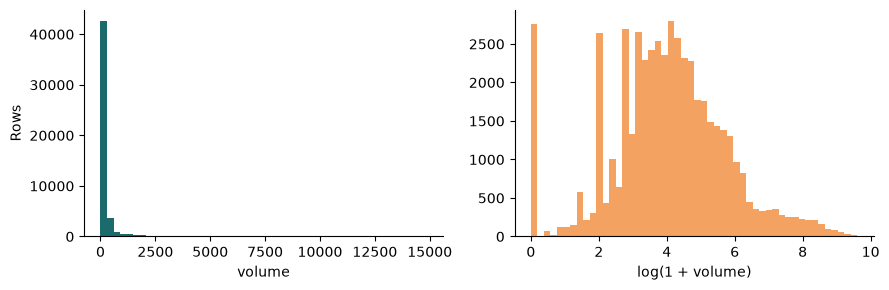

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3)); y = S[TGT].dropna().astype(float)
if y.nunique() <= 10:
    v = y.value_counts(normalize=True).sort_index() * 100; b = ax[0].bar(v.index.astype(str), v.values, color='#1B6B6D'); ax[0].bar_label(b, labels=['%.1f' % x for x in v.values], fontweight='bold'); ax[0].set_ylabel('Share of rows (%)')
    ax[1].axis('off'); print('class counts in the full table:', E[TGT].value_counts().to_dict())
else:
    ax[0].hist(y, bins=50, color='#1B6B6D'); ax[0].set_ylabel('Rows'); ax[0].set_xlabel(TGT)
    ax[1].hist(np.log1p(y.clip(lower=0)), bins=50, color='#F4A261'); ax[1].set_xlabel('log(1 + ' + TGT + ')')
    print(y.describe(percentiles=[.05, .5, .95]).round(3).to_dict())
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('report/fig_eda_target.png', dpi=200); plt.show()

### 2b.6 Phân phối các cột số chính

- **Làm gì:** tám biểu đồ tần suất, đã cắt 1% hai đầu để nhìn rõ phần chính.
- **Kiểm tra:** cột có hai đỉnh thường ứng với hai chế độ vận hành, nên tách ra khi phân tích.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

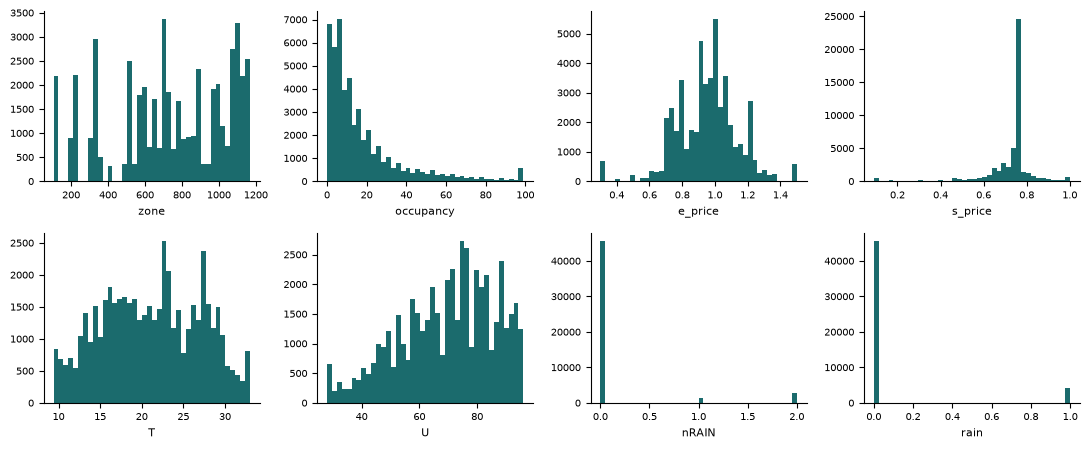

In [11]:
cols = [c for c in NUM if c != TGT][:8]; fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for a, c in zip(axes.ravel(), cols):
    x = S[c].dropna().astype(float); x = x.clip(x.quantile(.01), x.quantile(.99)); a.hist(x, bins=40, color='#1B6B6D'); a.set_xlabel(c, fontsize=8); a.spines[['top', 'right']].set_visible(False); a.tick_params(labelsize=7)
for a in axes.ravel()[len(cols):]: a.axis('off')
fig.tight_layout(); fig.savefig('report/fig_eda_distributions.png', dpi=200); plt.show()

### 2b.7 Giá trị ngoại lai

- **Làm gì:** tỷ lệ dòng nằm ngoài 1,5 lần khoảng tứ phân vị của từng cột.
- **Vì sao:** ngoại lai là lỗi đo thì loại và ghi nhật ký; là hiện tượng thật (đỉnh tải, sự cố) thì giữ và nêu trong bài.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [12]:
N_ = S[NUM].astype(float); q1, q3 = N_.quantile(.25), N_.quantile(.75); iqr = q3 - q1
out = (100 * ((N_ < q1 - 1.5 * iqr) | (N_ > q3 + 1.5 * iqr)).mean()).sort_values(ascending=False).round(2).rename('outside_1.5_IQR_pct')
out.to_csv('report/table_outliers.csv'); display(out.head(12).to_frame())

,outside_1.5_IQR_pct
s_price,16.85
volume,12.18
holiday,11.17
nRAIN,8.67
rain,8.67
occupancy,8.29
piles,5.47
festival,3.93
e_price,2.68
U,0.07


### 2b.8 Cột nào liên quan tới mục tiêu

- **Làm gì:** tương quan hạng Spearman giữa từng cột số và mục tiêu, vẽ mười cột mạnh nhất.
- **Vì sao:** đây là dự báo sớm về đặc trưng quan trọng; cột tương quan gần 1 có thể là rò rỉ và phải kiểm tra ý nghĩa.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,0
occupancy,0.813
piles,0.691
e_price,-0.243
s_price,-0.113
festival,-0.050
U,0.043
hour,-0.035
holiday,-0.020
T,0.011
zone,0.011


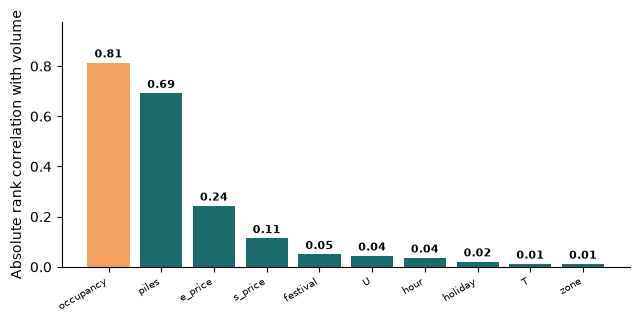

In [13]:
others = [c for c in NUM if c != TGT]
cor = S[others].astype(float).corrwith(S[TGT].astype(float), method='spearman').dropna(); cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(10)
cor.rename('spearman_with_target').to_csv('report/table_eda_correlation.csv'); display(cor.round(3).to_frame())
if len(cor) and cor.abs().max() > 0: bar_chart(cor.index, cor.abs().values, 'Absolute rank correlation with ' + TGT, 'report/fig_eda_correlation.png', highlight=0, fmt='{:.2f}')

### 2b.9 Các cột mạnh có trùng thông tin không

- **Làm gì:** ma trận tương quan giữa mục tiêu và bảy cột mạnh nhất.
- **Kiểm tra:** hai cột tương quan trên 0,95 với nhau thì chỉ cần giữ một khi giải thích kết quả.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

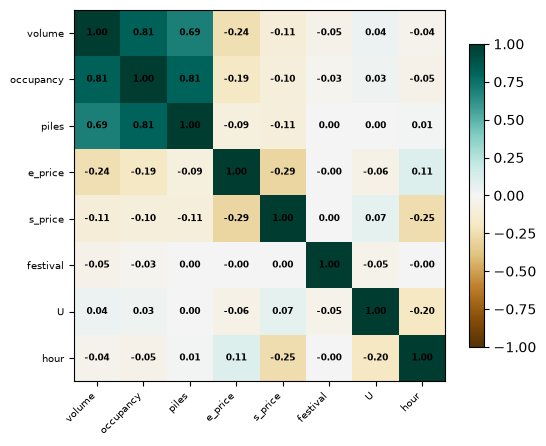

In [14]:
top = [TGT] + list(cor.index[:7]); m = S[top].astype(float).corr(method='spearman'); fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(m, cmap='BrBG', vmin=-1, vmax=1); ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top))); ax.set_xticklabels(top, rotation=45, ha='right', fontsize=7); ax.set_yticklabels(top, fontsize=7)
for i in range(len(top)):
    for j in range(len(top)): ax.text(j, i, '%.2f' % m.iloc[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
fig.colorbar(im, shrink=0.8); fig.tight_layout(); fig.savefig('report/fig_eda_heatmap.png', dpi=200); plt.show()

### 2b.10 Mục tiêu theo nhóm

- **Làm gì:** số dòng, trung bình, trung vị và độ lệch chuẩn của mục tiêu theo cột nhóm, kèm hình.
- **Vì sao:** khác biệt giữa các nhóm là gợi ý trực tiếp cho RQ1 và cho cách chia dữ liệu ở Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,rows,mean,median,std
hour,,,,
0,49775,393.702,63.000,1263.106
1,49775,400.276,63.000,1299.110
2,49775,354.455,63.000,1123.589
3,49775,331.437,63.000,1065.761
4,49775,328.928,63.000,1079.994
5,49775,337.487,63.000,1126.283
6,49775,369.616,62.417,1221.911
7,49775,368.889,56.000,1257.156
8,49775,263.697,52.500,878.541


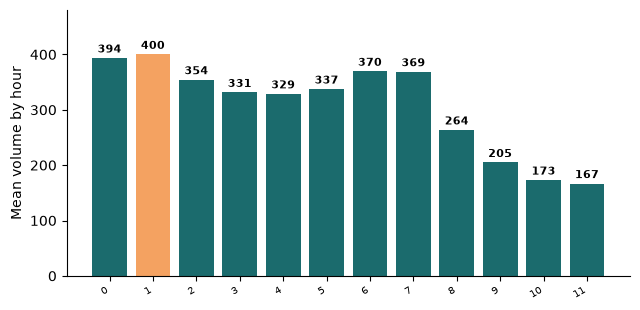

In [15]:
g = E.assign(_t=E[TGT].astype(float)).groupby(GRP)['_t'].agg(['size', 'mean', 'median', 'std']).rename(columns={'size': 'rows'})
g.to_csv('report/table_eda_by_group.csv'); display(g.sort_values('rows', ascending=False).head(15).round(3))
gg = g.sort_values('rows', ascending=False).head(12).sort_index()
if gg['mean'].min() >= 0 and gg['mean'].max() > 0: v, lab, f = nice(gg['mean'], 'Mean ' + TGT + ' by ' + GRP); bar_chart(gg.index.astype(str), v, lab, 'report/fig_eda_by_group.png', highlight=int(v.argmax()), fmt=f)

### Tổng hợp EDA

| Quan sát (có số) | Bằng chứng (bảng, hình) | Ảnh hưởng tới câu hỏi nào | Việc cần làm |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |
| | | | |

## Bước 3. Truy vấn dữ liệu bằng SQL

- **Làm gì:** ghi mọi truy vấn vào `sql/queries.sql`, rồi chạy **từng truy vấn một ô** để đọc kết quả và viết nhận xét.
- **Vì sao:** RQ1 được trả lời bằng bảng số; bảng `feat` là đầu vào của Notebook B.
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [16]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE ev AS SELECT * FROM 'data/processed/urbanev.parquet';
-- Q1: daily profile of charged energy per zone-hour on weekdays and weekends, with the electricity price
SELECT hour, AVG(CASE WHEN dow < 5 THEN volume END) AS weekday_kwh, AVG(CASE WHEN dow >= 5 THEN volume END) AS weekend_kwh, AVG(e_price) AS price FROM ev GROUP BY 1 ORDER BY 1;
-- Q2: the three regimes used in RQ3
SELECT CASE WHEN festival = 1 THEN 'Spring Festival' WHEN rain = 1 THEN 'rain' ELSE 'normal' END AS regime, COUNT(*) AS zone_hours,
       AVG(volume) AS mean_kwh, STDDEV(volume) AS sd_kwh FROM ev GROUP BY 1 ORDER BY 2 DESC;
-- Q3: zones ranked by mean demand, with their number of charging piles
SELECT zone, MIN(piles) AS piles, AVG(volume) AS mean_kwh, RANK() OVER (ORDER BY AVG(volume) DESC) AS rank FROM ev GROUP BY 1 ORDER BY 4 LIMIT 15;
-- Q4: model table; target is the energy charged in the zone 24 hours ahead; history is known now, tariff and calendar of the target hour are known in advance
CREATE OR REPLACE TABLE feat AS
WITH b AS (
  SELECT zone, ts, hour, piles, volume, occupancy, T, U, rain,
         LEAD(volume, 24) OVER w AS y, LEAD(ts, 24) OVER w AS ts_y, LEAD(e_price, 24) OVER w AS e_price_y, LEAD(s_price, 24) OVER w AS s_price_y,
         LEAD(holiday, 24) OVER w AS holiday_y, LEAD(festival, 24) OVER w AS festival_y, LEAD(dow, 24) OVER w AS dow_y, LEAD(rain, 24) OVER w AS rain_y,
         LAG(volume, 1) OVER w AS vol_lag1, LAG(volume, 24) OVER w AS vol_lag24, LAG(volume, 144) OVER w AS vol_same_hour_last_week,
         AVG(volume) OVER (PARTITION BY zone ORDER BY ts ROWS BETWEEN 23 PRECEDING AND CURRENT ROW) AS vol_mean24,
         AVG(volume) OVER (PARTITION BY zone ORDER BY ts ROWS BETWEEN 167 PRECEDING AND CURRENT ROW) AS vol_mean168,
         SIN(2 * PI() * hour / 24) AS hour_sin, COS(2 * PI() * hour / 24) AS hour_cos
  FROM ev WINDOW w AS (PARTITION BY zone ORDER BY ts))
SELECT * FROM b WHERE y IS NOT NULL AND vol_same_hour_last_week IS NOT NULL;
SELECT COUNT(*) AS n, COUNT(DISTINCT zone) AS zones, MIN(ts) AS first_ts, MAX(ts) AS last_ts FROM feat;
"""
open('sql/queries.sql', 'w').write(SQL)

2121

In [17]:
import duckdb
con = duckdb.connect(); QN = 0
def run(stmt):                                           # runs one statement; a SELECT is shown, saved and plotted when the result is small
    global QN
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if not body.upper().startswith(('SELECT', 'WITH', 'SUMMARIZE')): con.execute(stmt); print('done'); return None
    QN += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % QN, index=False); display(r.head(15))
    numc = [c for c in r.columns[1:] if pd.api.types.is_numeric_dtype(r[c])]
    if 2 <= len(r) <= 30 and numc and r[numc[0]].notna().all() and r[numc[0]].min() >= 0 and r[numc[0]].max() > 0:
        v, lab, f = nice(r[numc[0]], numc[0]); bar_chart(r.iloc[:, 0].astype(str), v, lab, 'report/fig_q%d.png' % QN, highlight=int(v.argmax()), fmt=f)
    return r

### Step 3: sql/queries.sql

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [18]:
r = run(r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE ev AS SELECT * FROM 'data/processed/urbanev.parquet';""")

done


### Q1: daily profile of charged energy per zone-hour on weekdays and weekends, with the electricity price

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,hour,weekday_kwh,weekend_kwh,price
0,0,394.261732,392.315039,0.907152
1,1,398.987554,403.471111,0.898850
2,2,352.772735,358.627047,0.898785
3,3,329.280454,336.788069,0.898786
4,4,326.224530,335.633262,0.898796
5,5,336.308232,340.410553,0.898782
6,6,370.591319,367.197347,0.898755
7,7,361.135741,388.123020,0.915421
8,8,253.162960,289.828061,0.948440
9,9,198.959303,219.571637,0.970476


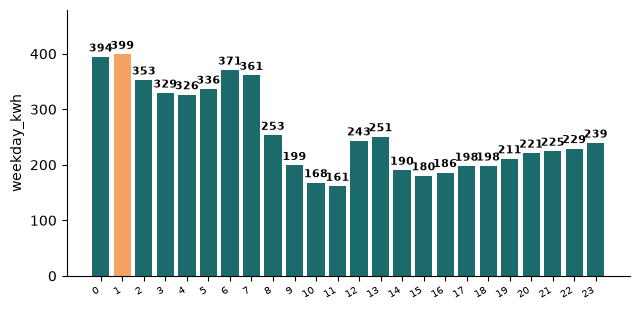

In [19]:
r = run(r"""-- Q1: daily profile of charged energy per zone-hour on weekdays and weekends, with the electricity price
SELECT hour, AVG(CASE WHEN dow < 5 THEN volume END) AS weekday_kwh, AVG(CASE WHEN dow >= 5 THEN volume END) AS weekend_kwh, AVG(e_price) AS price FROM ev GROUP BY 1 ORDER BY 1;""")

### Q2: the three regimes used in RQ3

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,regime,zone_hours,mean_kwh,sd_kwh
0,normal,1047750,264.965583,869.422484
1,rain,100650,275.752839,891.576642
2,Spring Festival,46200,135.943880,426.863029


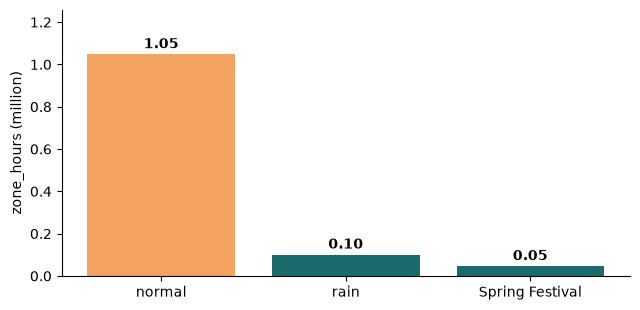

In [20]:
r = run(r"""-- Q2: the three regimes used in RQ3
SELECT CASE WHEN festival = 1 THEN 'Spring Festival' WHEN rain = 1 THEN 'rain' ELSE 'normal' END AS regime, COUNT(*) AS zone_hours,
       AVG(volume) AS mean_kwh, STDDEV(volume) AS sd_kwh FROM ev GROUP BY 1 ORDER BY 2 DESC;""")

### Q3: zones ranked by mean demand, with their number of charging piles

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,zone,piles,mean_kwh,rank
0,595,137,6745.565723,1
1,1167,373,5009.614727,2
2,844,66,3872.197667,3
3,633,135,3430.006100,4
4,1026,77,3166.652471,5
5,775,26,3074.249540,6
6,592,88,2943.653507,7
7,777,121,2765.598853,8
8,690,70,2688.970477,9
9,346,61,1938.482313,10


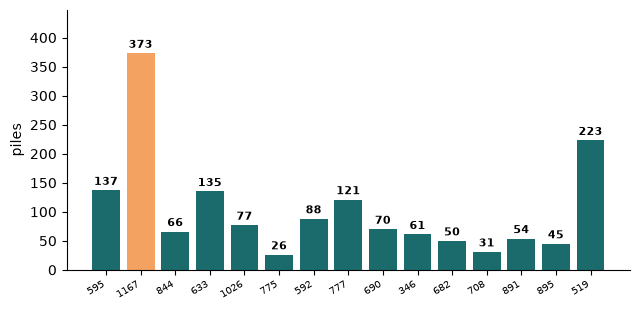

In [21]:
r = run(r"""-- Q3: zones ranked by mean demand, with their number of charging piles
SELECT zone, MIN(piles) AS piles, AVG(volume) AS mean_kwh, RANK() OVER (ORDER BY AVG(volume) DESC) AS rank FROM ev GROUP BY 1 ORDER BY 4 LIMIT 15;""")

### Q4: model table; target is the energy charged in the zone 24 hours ahead; history is known now, tariff and calendar of the target hour are known in advance

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [22]:
r = run(r"""-- Q4: model table; target is the energy charged in the zone 24 hours ahead; history is known now, tariff and calendar of the target hour are known in advance
CREATE OR REPLACE TABLE feat AS
WITH b AS (
  SELECT zone, ts, hour, piles, volume, occupancy, T, U, rain,
         LEAD(volume, 24) OVER w AS y, LEAD(ts, 24) OVER w AS ts_y, LEAD(e_price, 24) OVER w AS e_price_y, LEAD(s_price, 24) OVER w AS s_price_y,
         LEAD(holiday, 24) OVER w AS holiday_y, LEAD(festival, 24) OVER w AS festival_y, LEAD(dow, 24) OVER w AS dow_y, LEAD(rain, 24) OVER w AS rain_y,
         LAG(volume, 1) OVER w AS vol_lag1, LAG(volume, 24) OVER w AS vol_lag24, LAG(volume, 144) OVER w AS vol_same_hour_last_week,
         AVG(volume) OVER (PARTITION BY zone ORDER BY ts ROWS BETWEEN 23 PRECEDING AND CURRENT ROW) AS vol_mean24,
         AVG(volume) OVER (PARTITION BY zone ORDER BY ts ROWS BETWEEN 167 PRECEDING AND CURRENT ROW) AS vol_mean168,
         SIN(2 * PI() * hour / 24) AS hour_sin, COS(2 * PI() * hour / 24) AS hour_cos
  FROM ev WINDOW w AS (PARTITION BY zone ORDER BY ts))
SELECT * FROM b WHERE y IS NOT NULL AND vol_same_hour_last_week IS NOT NULL;""")

done


### Statement 6

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [23]:
r = run(r"""SELECT COUNT(*) AS n, COUNT(DISTINCT zone) AS zones, MIN(ts) AS first_ts, MAX(ts) AS last_ts FROM feat;""")

,n,zones,first_ts,last_ts
0,1148400,275,2022-09-07,2023-02-27 23:00:00


### Truy vấn bổ sung 1: hồ sơ của bảng làm việc

- **Làm gì:** `SUMMARIZE` cho biết min, max, số giá trị khác nhau và tỷ lệ thiếu của mọi cột bằng một lệnh SQL.
- **Kiểm tra:** so với bảng thống kê mô tả ở mục 2b.3.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,column_name,column_type,min,max,approx_unique,null_percentage
0,zone,BIGINT,102,1173,265,0.0
1,ts,TIMESTAMP,2022-09-01 00:00:00,2023-02-28 23:00:00,4884,0.0
2,volume,DOUBLE,0.0,16732.5,68683,0.0
3,occupancy,DOUBLE,0.0,373.0,313,0.0
4,e_price,DOUBLE,0.23806,1.8,1147,0.0
5,s_price,DOUBLE,0.0,1.45,1404,0.0
6,T,DOUBLE,8.3,34.7,233,0.0
7,U,BIGINT,21,97,78,0.0
8,nRAIN,BIGINT,0,3,4,0.0
9,rain,BIGINT,0,1,2,0.0


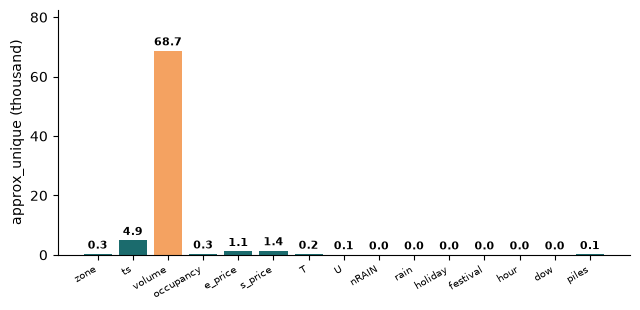

In [24]:
r = run('''SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE ev)''')

### Truy vấn bổ sung 2: các phân vị của mục tiêu

- **Làm gì:** phân vị 5%, 25%, 50%, 75%, 95% và 99% của cột mục tiêu.
- **Vì sao:** các phân vị này dùng để chọn ngưỡng, thang trục và cách cắt đuôi khi vẽ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [25]:
r = run('''SELECT COUNT(*) AS n, MIN("volume") AS min, QUANTILE_CONT("volume", 0.05) AS p05, QUANTILE_CONT("volume", 0.25) AS p25, MEDIAN("volume") AS p50, QUANTILE_CONT("volume", 0.75) AS p75, QUANTILE_CONT("volume", 0.95) AS p95, QUANTILE_CONT("volume", 0.99) AS p99, MAX("volume") AS max FROM ev''')

,n,min,p05,p25,p50,p75,p95,p99,max
0,1194600,0.0,0.0,18.666667,53.666667,152.541667,1044.0,4465.084167,16732.5


### Truy vấn bổ sung 3: xếp hạng các nhóm

- **Làm gì:** số dòng và trung bình mục tiêu theo nhóm, xếp hạng bằng hàm cửa sổ `RANK`, kèm tỷ trọng của nhóm trong toàn bảng.
- **Vì sao:** nhóm lớn nhất và nhóm lệch nhất thường là ví dụ minh hoạ trong mục Results.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,grp,mean_target,n,pct_of_rows,rank_by_mean
0,1,400.275648,49775,4.166667,1
1,0,393.702461,49775,4.166667,2
2,6,369.616255,49775,4.166667,3
3,7,368.888992,49775,4.166667,4
4,2,354.454637,49775,4.166667,5
5,5,337.486799,49775,4.166667,6
6,3,331.437338,49775,4.166667,7
7,4,328.927591,49775,4.166667,8
8,8,263.696580,49775,4.166667,9
9,13,248.543934,49775,4.166667,10


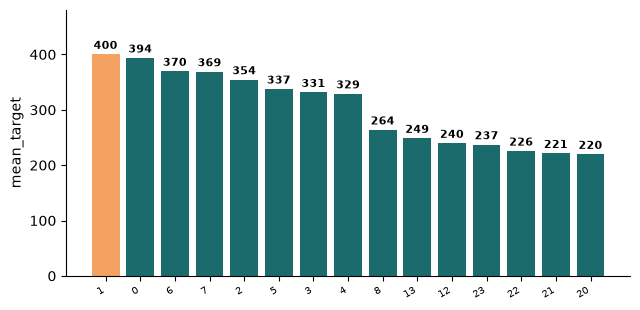

In [26]:
r = run('''SELECT CAST("hour" AS VARCHAR) AS grp, AVG("volume") AS mean_target, COUNT(*) AS n, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_rows, RANK() OVER (ORDER BY AVG("volume") DESC) AS rank_by_mean FROM ev GROUP BY 1 ORDER BY 5 LIMIT 15''')

### Truy vấn bổ sung 4: bảng mô hình có sạch không

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu và số giá trị khác nhau của từng cột trong bảng `feat`.
- **Kiểm tra:** cột đặc trưng nào còn thiếu thì phải xử lý trước khi sang Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [27]:
r = run('''SELECT column_name, column_type, null_percentage, approx_unique FROM (SUMMARIZE feat) ORDER BY null_percentage DESC LIMIT 20''')

,column_name,column_type,null_percentage,approx_unique
0,zone,BIGINT,0.0,265
1,ts,TIMESTAMP,0.0,4761
2,hour,INTEGER,0.0,24
3,piles,BIGINT,0.0,121
4,volume,DOUBLE,0.0,65700
5,occupancy,DOUBLE,0.0,313
6,T,DOUBLE,0.0,233
7,U,BIGINT,0.0,78
8,rain,BIGINT,0.0,2
9,y,DOUBLE,0.0,65700


## Bước 5. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

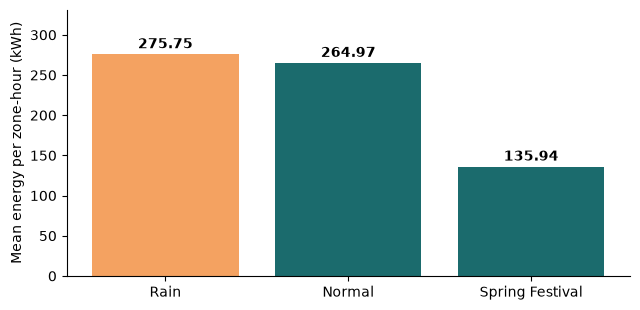

In [28]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT CASE WHEN festival = 1 THEN 'Spring Festival' WHEN rain = 1 THEN 'Rain' ELSE 'Normal' END AS g, AVG(volume) AS v FROM ev GROUP BY 1 ORDER BY 2 DESC""").df()
bar_chart(fig1.g, fig1.v, 'Mean energy per zone-hour (kWh)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [29]:
import json, hashlib
path = 'data/processed/urbanev.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/urbanev.parquet', 'rows': 1194600, 'columns': 15, 'feat_rows': 1148400, 'md5': '994e49927b48046a1f544299570a91f4'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: